# 사진 한 장을 스캔본으로: 배열에서 앱까지

목표는 E01 사진의 **입력 → 전처리 → 엣지 → 윤곽선·후보 → 좌표 정렬 → 투시 변환 → 이진화**를
따라가고, 친구에게 앱의 결과와 실패 이유를 설명하는 것이다. Python 기본 변수·반복문부터 출발한다.
먼저 셀을 위에서 아래로 실행한다. 각 그림과 표를 읽은 뒤 마지막 시연 순서로 앱을 연다.

핵심 한 사례에서는 계산을 펼치고, 다음 사진부터는 `src`의 기존 함수를 재사용한다.
본문은 하나로 이어지지만 **기본 처리**와 **보너스·확장**은 구분한다.
합성 20장은 꼭짓점 정답이 있는 제한된 실험이며 실제 휴대폰 사진의 성능을 대표하지 않는다.
이 노트북은 원본 사진·기존 실험 파일을 수정하지 않는다.

실행 환경: A3-1에서 `uv sync --group dev` 후 해당 `.venv`의 Python을 노트북 커널로 선택한다.
Jupyter/VS Code에서 이 파일을 열거나 `uv run --group dev python tools/build_learning_notebook.py --execute`로
재생성·전체 실행한다. 전체 탐색은 5,320회 검출하므로 잠시 걸린다.

In [1]:
from pathlib import Path
import sys
import json
import platform
from dataclasses import replace
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# A3-1 또는 notebooks 폴더에서 실행한다. 사용자별 절대 경로를 넣지 않는다.
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root / 'src/scanner.py').is_file(), 'A3-1 또는 notebooks에서 실행하세요.'
sys.path.insert(0, str(root))
from src import scanner, geometry, evaluate, convolution
from src.image_io import imread

cv2.setNumThreads(2)
np.set_printoptions(precision=3, suppress=True)
print('Python', platform.python_version(), 'OpenCV', cv2.__version__, 'NumPy', np.__version__)

def table(headers, rows):
    lines = [' | '.join(headers), ' | '.join(['---'] * len(headers))]
    for row in rows:
        lines.append(' | '.join(str(value) for value in row))
    display(Markdown('\n'.join(lines)))

def show_images(items, columns=3):
    # 표시만 담당한다. 이미지 처리 계산은 각 단계 셀에서 한다.
    rows = (len(items) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.8 * rows), squeeze=False)
    for axis in axes.flat:
        axis.axis('off')
    for axis, (name, image) in zip(axes.flat, items):
        if image.ndim == 3:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        axis.imshow(image, cmap='gray', vmin=0, vmax=255)
        axis.set_title(name)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

def arrays(items):
    rows = []
    for name, image in items:
        rows.append([name, image.shape, image.dtype, int(image.min()), int(image.max())])
    table(['배열', 'shape', 'dtype', '최솟값', '최댓값'], rows)

Python 3.12.13 OpenCV 5.0.0 NumPy 2.5.4


## 1. 입력과 축소: 좌표의 단위부터

`image.shape`는 **(높이 H, 너비 W, 채널)**, 픽셀 접근은 `image[y, x]`다.
좌표는 반대로 `(x, y)`라고 쓴다. OpenCV 색 순서는 BGR, 그림 표시 순서는 RGB다.
`uint8`은 0~255 정수다. 이 상태로 뺄셈하면 음수가 감길 수 있어 계산할 때 실수로 바꾼다.

검출은 긴 변 960px 축소본에서 하고, 최종 변환은 원본에서 한다. 좌표가 어느 이미지의 단위인지
구분해야 한다. `scale`은 원본 → 축소본 배율이다. 일반 크기는 정수 반올림 오차도 생긴다.
E01에서는 두 축 모두 정확히 0.75배다. **확인:** (x,y)=(100,200) 픽셀은 배열의 어디인가?

배율: 0.75 BGR 픽셀 image[200,100]: [69 68 72]


배열 | shape | dtype | 최솟값 | 최댓값
--- | --- | --- | --- | ---
original | (1280, 960, 3) | uint8 | 20 | 255
work | (960, 720, 3) | uint8 | 26 | 255

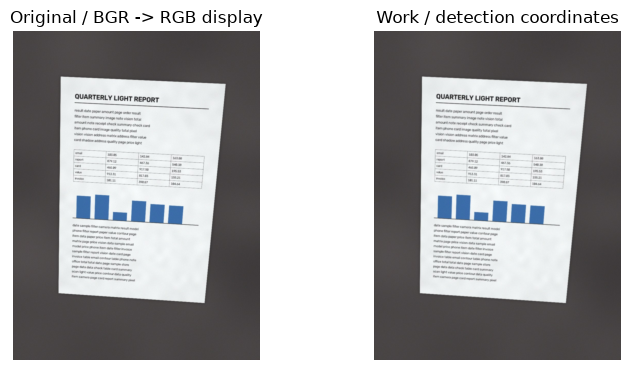

In [2]:
image = imread(root / 'data/synthetic/E01.jpg')
original_copy = image.copy()
params = scanner.ScanParams().normalized()
height, width = image.shape[:2]
scale = min(1.0, params.work_size / max(height, width))
work = cv2.resize(image, (round(width * scale), round(height * scale)), interpolation=cv2.INTER_AREA)
print('배율:', scale, 'BGR 픽셀 image[200,100]:', image[200, 100])
arrays([('original', image), ('work', work)])
show_images([('Original / BGR -> RGB display', image), ('Work / detection coordinates', work)], 2)

## 2. 전처리: 한 픽셀의 밝기와 블러 직접 계산

회색 밝기는 약 `0.114 B + 0.587 G + 0.299 R`. OpenCV 정수 연산과 반올림 때문에 실수식과
1 정도 차이가 날 수 있다. 가우시안 블러는 주변 픽셀과 커널의 **원소곱을 모두 더한 값**이다.
아래는 E01의 5×5 조각 하나를 펼친다. 커널 합이 1이므로 균일한 밝기는 보존된다.
경계 처리 차이를 피하려고 이미지 내부 픽셀을 고른다. 실수 블러와 uint8 블러의 반올림도 구분한다.

B,G,R: 161.0 161.0 161.0 가중 밝기: 161.0 OpenCV gray: 161
5×5 픽셀 조각:
 [[ 71.  69.  71.  69.  69.]
 [ 69.  76.  93. 102. 103.]
 [ 70. 102. 161. 191. 200.]
 [ 71. 114. 185. 222. 233.]
 [ 71. 114. 191. 230. 237.]] 
커널:
 [[0.004 0.016 0.023 0.016 0.004]
 [0.016 0.062 0.094 0.062 0.016]
 [0.023 0.094 0.141 0.094 0.023]
 [0.016 0.062 0.094 0.062 0.016]
 [0.004 0.016 0.023 0.016 0.004]] 
원소곱:
 [[ 0.277  1.078  1.664  1.078  0.27 ]
 [ 1.078  4.75   8.719  6.375  1.609]
 [ 1.641  9.562 22.641 17.906  4.688]
 [ 1.109  7.125 17.344 13.875  3.641]
 [ 0.277  1.781  4.477  3.594  0.926]]
합: 137.484375 uint8 블러: 137


배열 | shape | dtype | 최솟값 | 최댓값
--- | --- | --- | --- | ---
gray | (960, 720) | uint8 | 27 | 252
blurred | (960, 720) | uint8 | 48 | 250

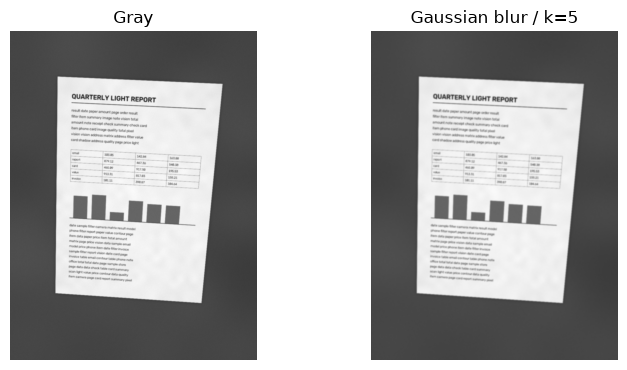

In [3]:
gray = cv2.cvtColor(work, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (params.blur, params.blur), 0)
y, x = 132, 139
b, g, r = work[y, x].astype(float)
gray_float = 0.114 * b + 0.587 * g + 0.299 * r
kernel_1d = cv2.getGaussianKernel(params.blur, 0)
kernel = kernel_1d @ kernel_1d.T
radius = params.blur // 2
patch = gray[y-radius:y+radius+1, x-radius:x+radius+1].astype(float)
weighted = patch * kernel
manual_blur = weighted.sum()
float_blur = cv2.GaussianBlur(gray.astype(float), (params.blur, params.blur), 0)
print('B,G,R:', b, g, r, '가중 밝기:', gray_float, 'OpenCV gray:', gray[y,x])
print('5×5 픽셀 조각:\n', patch, '\n커널:\n', kernel, '\n원소곱:\n', weighted)
print('합:', manual_blur, 'uint8 블러:', blurred[y,x])
np.testing.assert_allclose(manual_blur, float_blur[y,x], atol=1e-10)
assert abs(gray_float - int(gray[y,x])) <= 1
assert abs(manual_blur - int(blurred[y,x])) <= 1
np.testing.assert_allclose(kernel.sum(), 1)
arrays([('gray', gray), ('blurred', blurred)])
show_images([('Gray', gray), ('Gaussian blur / k=5', blurred)], 2)

## 3. 엣지와 닫힘: 밝은 픽셀을 고르는 것이 아니다

Canny는 밝기 **변화의 기울기**를 계산하고, 얇은 극댓값을 남긴 뒤 두 임계값으로 연결된 선을 추적한다.
`high` 이상은 강한 엣지, `low`~`high`는 강한 엣지와 연결될 때 남는다.
흰 종이 자체가 밝다고 전부 엣지가 되지는 않는다. 출력 255는 엣지 표시이며 원래 밝기가 아니다.
닫힘은 팽창 → 침식으로 작은 틈을 잇지만 배경 무늬까지 연결할 수 있다.
앱의 `3 Edges`는 닫힘 **전** Canny다. 윤곽선 검출 입력은 그 뒤의 `closed`다.

엣지 픽셀 수: 20191 닫힘 후: 30800
엣지의 고유 값: [  0 255]


배열 | shape | dtype | 최솟값 | 최댓값
--- | --- | --- | --- | ---
edges | (960, 720) | uint8 | 0 | 255
closed | (960, 720) | uint8 | 0 | 255

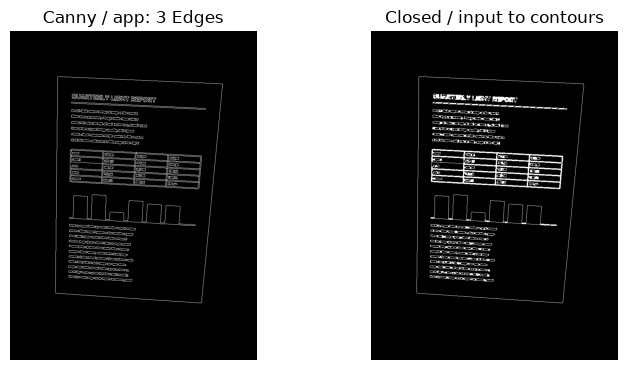

In [4]:
edges = cv2.Canny(blurred, params.canny_low, params.canny_high)
close_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (params.close_kernel, params.close_kernel))
closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, close_kernel)
print('엣지 픽셀 수:', np.count_nonzero(edges), '닫힘 후:', np.count_nonzero(closed))
print('엣지의 고유 값:', np.unique(edges))
arrays([('edges', edges), ('closed', closed)])
show_images([('Canny / app: 3 Edges', edges), ('Closed / input to contours', closed)], 2)

## 4. 윤곽선에서 문서 후보 고르기

윤곽선 하나는 `(N,1,2)` 점 배열이고, 전체는 길이가 서로 다른 배열들의 리스트다.
면적순으로 읽으며 면적이 화면의 5~98%인지, 둘레의 2% 오차로 근사했을 때 꼭짓점이 4개인지,
볼록한지 검사한다. 통과한 사각형 중 원래 윤곽선 면적이 가장 큰 것을 고른다.
**사각형 검출은 문서 정답 판정과 다르다.** 큰 액자나 배경 타일도 이 규칙을 통과할 수 있다.
`candidates`는 면적만 통과한 근사 다각형이므로 모두 사각형이라는 뜻도 아니다.

In [5]:
contours, hierarchy = cv2.findContours(closed, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
sorted_contours = sorted(contours, key=cv2.contourArea, reverse=True)
image_area = closed.shape[0] * closed.shape[1]
candidate_rows = []
raw_quad = None
best_area = 0
for contour in sorted_contours:
    area = cv2.contourArea(contour)
    if area < params.min_area_ratio * image_area:
        break
    if area > params.max_area_ratio * image_area:
        continue
    perimeter = cv2.arcLength(contour, True)
    epsilon_px = params.approx_epsilon * perimeter
    approx = cv2.approxPolyDP(contour, epsilon_px, True)
    convex = geometry.is_convex(approx)
    candidate_rows.append([round(area, 1), round(area/image_area, 3), len(contour),
                           round(epsilon_px, 2), len(approx), convex])
    if len(approx) == 4 and convex and area > best_area:
        raw_quad = approx.reshape(4, 2).astype(float)
        best_area = area
print('윤곽선 수:', len(contours), '첫 윤곽선 shape/dtype:', contours[0].shape, contours[0].dtype)
table(['면적 px²', '화면 비율', '원래 점 수', '허용 오차 px', '근사 점 수', '볼록'], candidate_rows)
assert raw_quad is not None
print('선택된 네 점 (아직 순서 없음):\n', raw_quad)

윤곽선 수: 374 첫 윤곽선 shape/dtype: (16, 1, 2) int32


면적 px² | 화면 비율 | 원래 점 수 | 허용 오차 px | 근사 점 수 | 볼록
--- | --- | --- | --- | --- | ---
289978.0 | 0.42 | 246 | 44.57 | 4 | True
289974.0 | 0.42 | 244 | 44.51 | 4 | True
36761.0 | 0.053 | 137 | 19.52 | 4 | True

선택된 네 점 (아직 순서 없음):
 [[139. 132.]
 [133. 764.]
 [558. 793.]
 [620. 153.]]


## 5. 좌표 정렬과 원본 좌표 복원

평균 중심에서 각 점으로 향하는 `atan2(dy,dx)` 각도를 구해 시계 방향으로 잇는다.
이미지에서는 y가 아래로 커지므로 각도 오름차순이 화면의 시계 방향이다.
다음 점으로 향하는 변 중 `dx/길이`가 가장 큰 변을 윗변으로 정하고 그 시작점을 TL로 삼는다.
TL·TR·BR·BL은 이 규칙으로 붙인 이름이다. 글자의 읽는 방향을 인식하지 않아 90° 회전은 남을 수 있다.
`roll`은 행 순서를 순환 이동한다. 네 점을 각각 `scale`로 나누면 원본 픽셀 좌표가 된다.

In [6]:
center = raw_quad.mean(axis=0)
angles = np.arctan2(raw_quad[:,1] - center[1], raw_quad[:,0] - center[0])
order = np.argsort(angles, kind='stable')
clockwise = raw_quad[order]
vectors = np.roll(clockwise, -1, axis=0) - clockwise
lengths = np.linalg.norm(vectors, axis=1)
alignment = vectors[:,0] / lengths
start = int(np.argmax(np.round(alignment, 12)))
quad_work = np.roll(clockwise, -start, axis=0)
quad = quad_work / scale
print('중심:', center, '각도 rad:', angles, '정렬 순서:', order)
print('시계 방향 변 벡터:\n', vectors, '\ndx/길이:', alignment, '시작 행:', start)
table(['이름', '축소본 (x,y)', '원본 (x,y)'], zip(scanner.CORNER_NAMES, quad_work, quad))
np.testing.assert_allclose(quad_work, geometry.order_points(raw_quad))
assert len(np.unique(quad, axis=0)) == 4
np.testing.assert_allclose(geometry.polygon_area(quad), geometry.polygon_area(quad_work)/scale**2)

중심: [362.5 460.5] 각도 rad: [-2.168  2.218  1.039 -0.874] 정렬 순서: [0 3 2 1]
시계 방향 변 벡터:
 [[ 481.   21.]
 [ -62.  640.]
 [-425.  -29.]
 [   6. -632.]] 
dx/길이: [ 0.999 -0.096 -0.998  0.009] 시작 행: 0


이름 | 축소본 (x,y) | 원본 (x,y)
--- | --- | ---
TL | [139. 132.] | [185.333 176.   ]
TR | [620. 153.] | [826.667 204.   ]
BR | [558. 793.] | [ 744.    1057.333]
BL | [133. 764.] | [ 177.333 1018.667]

## 6. 투시 변환: 네 점의 대응에서 픽셀까지

먼저 **거리 기반 크기**로 기본 기하를 배운다. 윗변·아랫변 중 긴 길이를 너비로,
왼변·오른변 중 긴 길이를 높이로 삼는다. 목적지 순서도 TL·TR·BR·BL이다.
원근 때문에 이 길이가 실제 종횡비를 보장하지는 않는다. 앱 기본값은 뒤에서 비교할 Zhang 확장이다.

3×3 행렬 M의 마지막 원소를 1로 놓으면 미지수는 8개다.
`(u,v,1)`은 `M @ (x,y,1)`의 마지막 값으로 나눈 좌표다.
점 하나가 `u=(a*x+b*y+c)/(g*x+h*y+1)`, `v=(d*x+e*y+f)/(g*x+h*y+1)`라는
방정식 두 개를 준다. 네 점에서 만든 8개 방정식을 풀고 OpenCV 결과와 비교한다.

둘째 점의 방정식 두 행:
 [[    826.667     204.          1.          0.          0.          0.
  -529893.346 -130764.   ]
 [      0.          0.          0.        826.667     204.          1.
       -0.         -0.   ]] 
우변: [np.float64(641.0), np.float64(0.0)]
직접 푼 M:
 [[ 1.00041037e+00  9.49756655e-03 -1.87080955e+02]
 [-3.85944933e-02  8.83997715e-01 -1.48430752e+02]
 [ 3.44580229e-05 -1.33038176e-04  1.00000000e+00]]
변환된 네 점:
 [[ -0.   0.]
 [641.   0.]
 [641. 856.]
 [  0. 856.]] 
목적지:
 [[  0.   0.]
 [641.   0.]
 [641. 856.]
 [  0. 856.]]
출력 중앙 픽셀의 원본 좌표: [479.791 639.813]


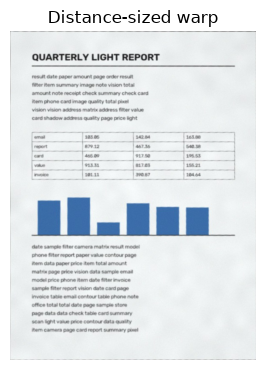

In [7]:
tl, tr, br, bl = quad
out_width = max(1, round(max(np.linalg.norm(tr-tl), np.linalg.norm(br-bl))))
out_height = max(1, round(max(np.linalg.norm(bl-tl), np.linalg.norm(br-tr))))
assert (out_width, out_height) == geometry.output_size_by_distance(quad)
# OpenCV와 같은 float32 입력을 실수 연립방정식으로 푼다.
source = quad.astype(np.float32)
destination = np.float32([[0,0], [out_width-1,0], [out_width-1,out_height-1], [0,out_height-1]])
equations, answers = [], []
for (x,y), (u,v) in zip(source.astype(float), destination.astype(float)):
    equations.append([x,y,1,0,0,0,-u*x,-u*y])
    answers.append(u)
    equations.append([0,0,0,x,y,1,-v*x,-v*y])
    answers.append(v)
coefficients = np.linalg.solve(np.array(equations), np.array(answers))
manual_matrix = np.append(coefficients, 1).reshape(3,3)
distance_warp, matrix = scanner.warp_document(image, quad, 'distance')
print('둘째 점의 방정식 두 행:\n', np.array(equations[2:4]), '\n우변:', answers[2:4])
# 작은 원근 계수를 0처럼 보이지 않게 출력한다.
with np.printoptions(precision=8, suppress=False):
    print('직접 푼 M:\n', manual_matrix)
np.testing.assert_allclose(manual_matrix, matrix, rtol=1e-5, atol=1e-5)
homogeneous = np.column_stack([source, np.ones(4)])
projected = homogeneous @ manual_matrix.T
mapped = projected[:,:2] / projected[:,2:]
print('변환된 네 점:\n', mapped, '\n목적지:\n', destination)
np.testing.assert_allclose(mapped, destination, atol=1e-5)
# 영상 보간은 OpenCV에 맡긴다. 결과 픽셀에서 원본으로 역매핑하고 주변 색을 보간한다.
inverse = np.linalg.inv(manual_matrix)
output_center = np.array([out_width//2, out_height//2, 1])
origin = inverse @ output_center
print('출력 중앙 픽셀의 원본 좌표:', origin[:2]/origin[2])
show_images([('Distance-sized warp', distance_warp)], 1)

## 7. 적응형 이진화와 기존 scan() 연결

주변 가우시안 평균에서 C를 뺀 임계값보다 밝으면 255, 아니면 0으로 만든다.
C를 올리면 임계값이 낮아져 흰 부분이 늘어난다. 블록 크기는 주변을 얼마나 넓게 보는지 정한다.
기본 0은 결과의 짧은 변을 기준으로 홀수 블록을 자동 선택한다.
아래는 내부 픽셀 한 점에서 지역 가중 평균·반올림·비교를 직접 확인한다.
이진화는 **이미 정한 좌표나 잘린 모서리를 복구하지 않는다.**

block: 33 중심 밝기: 248 지역 평균: 247.89298116110547
정수 평균 - C: 238 직접 비교: 255


배열 | shape | dtype | 최솟값 | 최댓값
--- | --- | --- | --- | ---
warped | (857, 642, 3) | uint8 | 19 | 255
scanned | (857, 642) | uint8 | 0 | 255

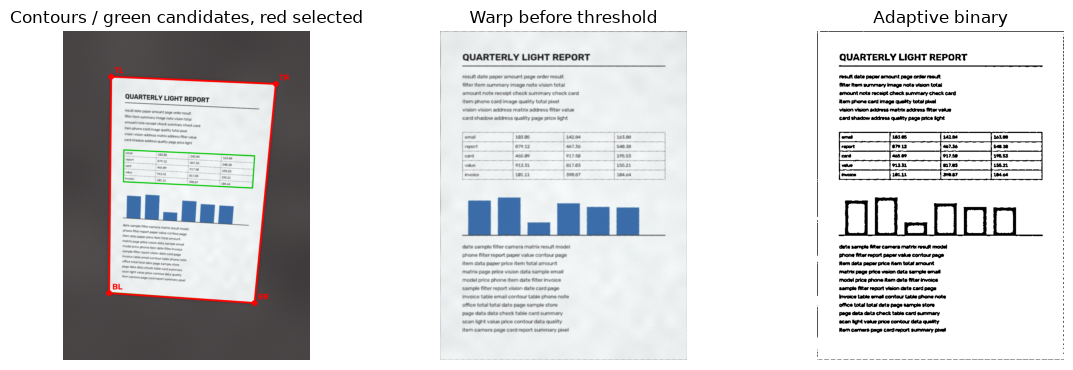

모든 중간 결과가 기존 scan()과 일치하며 입력 원본도 보존됨


In [8]:
warp_gray = cv2.cvtColor(distance_warp, cv2.COLOR_BGR2GRAY)
block = scanner.auto_block_size(warp_gray.shape)
local_weights = cv2.getGaussianKernel(block, 0)
local_kernel = local_weights @ local_weights.T
y, x = warp_gray.shape[0]//2, warp_gray.shape[1]//2
radius = block//2
local_patch = warp_gray[y-radius:y+radius+1, x-radius:x+radius+1].astype(float)
mean_float = (local_patch * local_kernel).sum()
mean_uint8 = int(np.rint(mean_float))
pixel = int(warp_gray[y,x])
binary_pixel = 255 if pixel > mean_uint8 - params.thresh_c else 0
scanned_distance = cv2.adaptiveThreshold(warp_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, block, params.thresh_c)
print('block:', block, '중심 밝기:', pixel, '지역 평균:', mean_float)
print('정수 평균 - C:', mean_uint8 - params.thresh_c, '직접 비교:', binary_pixel)
assert binary_pixel == scanned_distance[y,x]
np.testing.assert_array_equal(scanned_distance, scanner.enhance(distance_warp, 0, params.thresh_c))
# 같은 거리 모드로 전체 파이프라인을 호출해 앞의 중간 배열과 대조한다.
distance_params = replace(params, aspect='distance')
result = scanner.scan(image, distance_params)
for name, manual in [('work',work), ('gray',gray), ('blurred',blurred), ('edges',edges),
                     ('closed',closed), ('quad_work',quad_work), ('quad',quad),
                     ('warped',distance_warp), ('scanned',scanned_distance)]:
    np.testing.assert_array_equal(manual, getattr(result, name))
np.testing.assert_array_equal(image, original_copy)
arrays([('warped',distance_warp), ('scanned',scanned_distance)])
show_images([('Contours / green candidates, red selected', scanner.draw_contours(result)),
             ('Warp before threshold', distance_warp), ('Adaptive binary', scanned_distance)])
print('모든 중간 결과가 기존 scan()과 일치하며 입력 원본도 보존됨')

## 8. 앱의 기본값과 반환 객체 읽기

`ScanParams`는 설정, `ScanResult`는 그 설정으로 계산한 배열·좌표·판정 전 상태다.
`frozen=True`인 설정은 값을 덮어쓰지 않고 `replace`로 새 객체를 만든다.
`found`는 `quad is not None`이라는 속성이며 정확도 점수가 아니다.
실패하면 `quad`, `warped`, `scanned`가 None이다. `warp=False`는 검출만 하므로 found여도 영상은 None이다.
앱 기본값은 `aspect='zhang'`: 카메라 모델로 종횡비를 추정한다(보너스가 기본 설정에 연결됨).
기본 경로에 규칙 실험용 `color_edges`, `auto_canny`, `clahe`는 모두 꺼져 있다.

설정: {'blur': 5, 'canny_low': 50, 'canny_high': 150, 'close_kernel': 3, 'min_area_ratio': 0.05, 'max_area_ratio': 0.98, 'approx_epsilon': 0.02, 'work_size': 960, 'aspect': 'zhang', 'block_size': 0, 'thresh_c': 10, 'color_edges': False, 'auto_canny': False, 'clahe': False}
found: True 원본 → 축소 배율: 0.75
종횡비 dict: {'estimated': 0.7057986345372645, 'focal_px': 965.3716434732032, 'method': 'zhang'}


배열 | shape | dtype | 최솟값 | 최댓값
--- | --- | --- | --- | ---
app warped | (883, 623, 3) | uint8 | 20 | 255
app scanned | (883, 623) | uint8 | 0 | 255

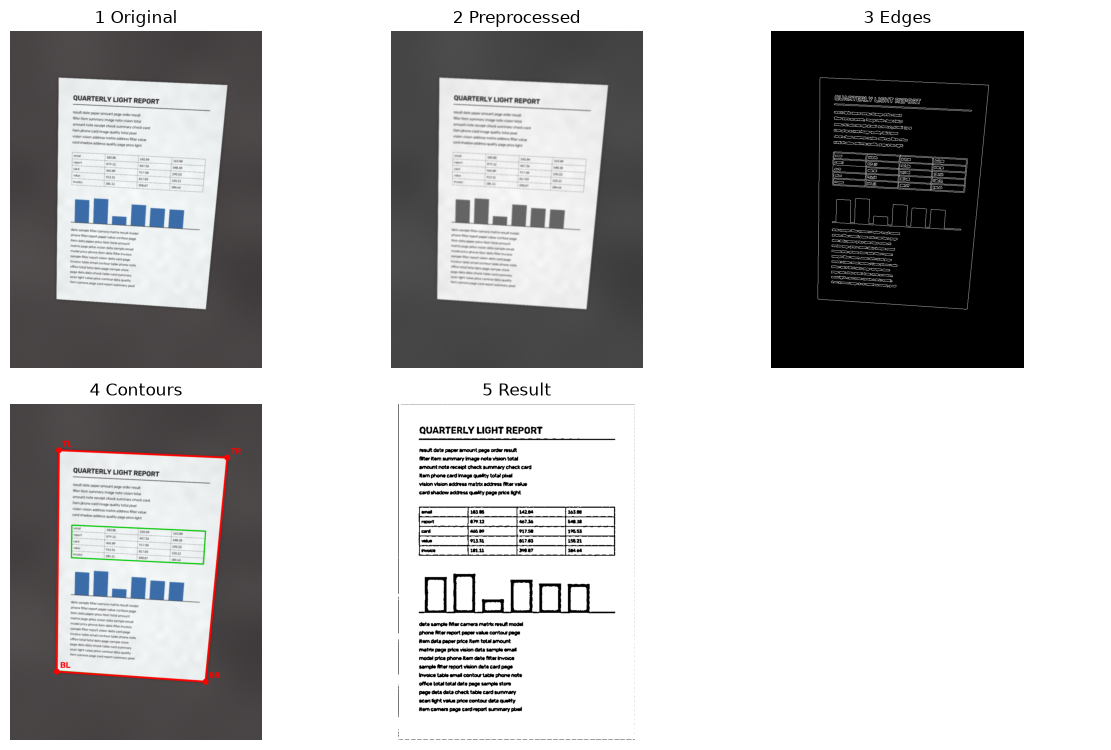

In [9]:
app_result = scanner.scan(image, params)
print('설정:', app_result.params.to_dict())
print('found:', app_result.found, '원본 → 축소 배율:', app_result.scale)
print('종횡비 dict:', app_result.aspect)
arrays([('app warped',app_result.warped), ('app scanned',app_result.scanned)])
stages = scanner.stage_images(app_result)
show_images(list(stages.items()))

위 그림의 `1 Original`은 화면 표시용 축소본이다. `2 Preprocessed`는 블러한 회색,
`3 Edges`는 Canny, `4 Contours`는 면적 통과 후보 초록·선택 빨강,
`5 Result`는 원본 해상도에서 편 뒤 이진화한 결과다. 표시를 위해 회색을 3채널 BGR로 바꾸지만
계산 배열 `scanned` 자체는 2차원이다. 다섯 창만으로 숨겨지는 `closed`와 `warped`는 앞에서 따로 보았다.

## 9. 파라미터 한 가지씩: 어느 경계부터 바뀌는가

| 조작 | 직접 바뀌는 곳 | 뒤따라 바뀔 수 있는 곳 |
| --- | --- | --- |
| Blur Kernel | 전처리 | 엣지·후보·좌표·최종 결과 |
| Canny Low / High | 엣지 | 후보·좌표·최종 결과 |
| Thresh Block / C | 변환 후 이진화 | 흑백 결과만 (좌표는 그대로) |
| close / 면적 / epsilon (코드 설정) | 닫힘 / 후보 선택 | 좌표·변환 결과 |
| aspect (명령줄) | 결과 크기 | 종횡비·자동 블록·이진화 |

짝수 blur=4는 5가 되고 low>high면 둘을 정렬한다. 트랙바 표시값과 실제 적용값을 구분한다.
아래는 고정 E01에 각 항목만 바꾼 **민감도 실험**이다. 최적값 탐색과 구별해서 읽는다.
실행 전에 C를 올리면 어떤 그림이 바뀔지 예측해 보자.

설정 | 바뀐 엣지 픽셀 수 | 좌표 동일 | 바뀐 이진 픽셀 수
--- | --- | --- | ---
default | 0 | True | 0
blur=11 | 14997 | False | 크기 다름 또는 검출 실패
low=150 high=300 | 13560 | True | 0
C=20 | 0 | True | 11851
block=81 | 0 | True | 19075

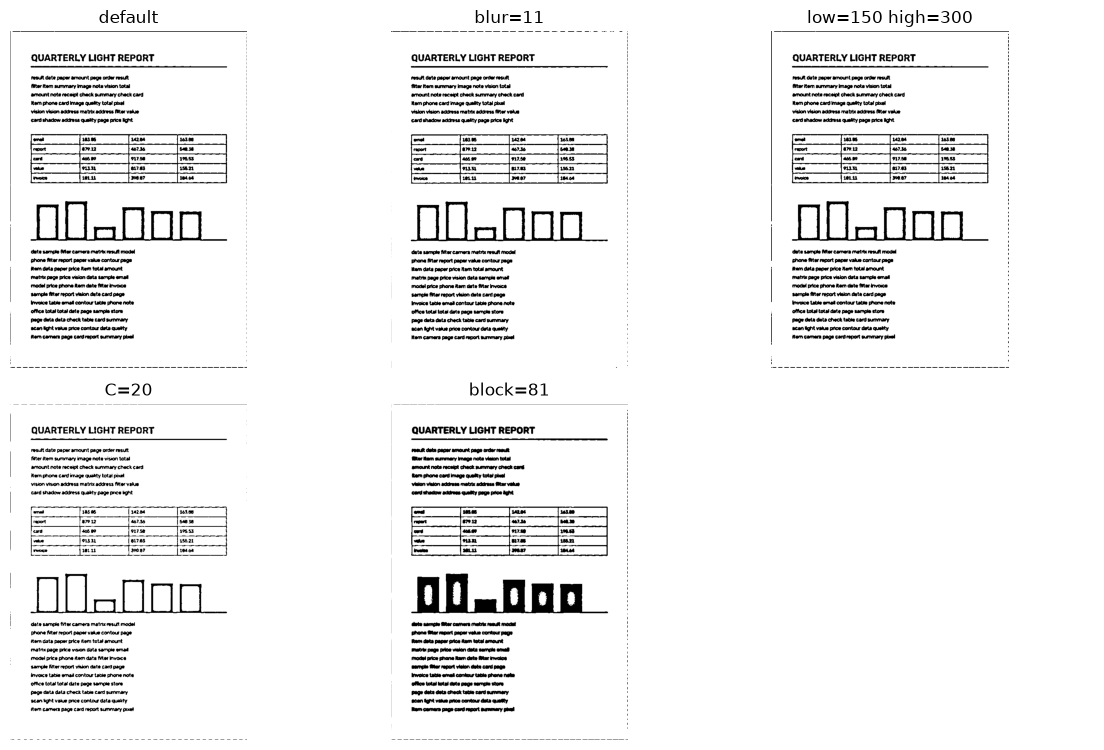

입력: 4 200 80
적용: 5 80 200


In [10]:
variants = [('default', params), ('blur=11', replace(params,blur=11)),
            ('low=150 high=300', replace(params,canny_low=150,canny_high=300)),
            ('C=20', replace(params,thresh_c=20)), ('block=81', replace(params,block_size=81))]
sensitivity_rows, sensitivity_images = [], []
for name, setting in variants:
    changed = scanner.scan(image, setting)
    edge_delta = np.count_nonzero(changed.edges != app_result.edges)
    quad_same = changed.found and np.array_equal(changed.quad, app_result.quad)
    binary_delta = '크기 다름 또는 검출 실패'
    if changed.found and changed.scanned.shape == app_result.scanned.shape:
        binary_delta = np.count_nonzero(changed.scanned != app_result.scanned)
    sensitivity_rows.append([name, edge_delta, quad_same, binary_delta])
    sensitivity_images.append((name, scanner.stage_images(changed)['5 Result']))
    if name in ('C=20', 'block=81'):
        np.testing.assert_array_equal(changed.quad, app_result.quad)
        np.testing.assert_array_equal(changed.warped, app_result.warped)
table(['설정', '바뀐 엣지 픽셀 수', '좌표 동일', '바뀐 이진 픽셀 수'], sensitivity_rows)
show_images(sensitivity_images)
unusual = scanner.ScanParams(blur=4,canny_low=200,canny_high=80)
print('입력:', unusual.blur, unusual.canny_low, unusual.canny_high)
normalized = unusual.normalized()
print('적용:', normalized.blur, normalized.canny_low, normalized.canny_high)

## 10. 성공·실패를 같은 조건으로 재평가

`load_dataset`은 `(label 사전, BGR 배열)` 쌍의 리스트를 준다. `label['corners']`는 검증용 정답이며
검출 함수에 넘기지 않는다. 정답의 긴 대각선 D로 최대 꼭짓점 오차를 나눈 값이 2% 이하면 성공,
5% 이하면 부분 성공, 그 밖에는 실패다. 시작점의 90° 단위 순환 이동은 맞춰 비교하고 따로 기록한다.
이 평가는 **꼭짓점 위치**에 관한 것이며 글자 가독성·OCR·종횡비 정확성의 종합 점수가 아니다.

현재 파일과 기본 설정으로 20장을 다시 처리하고 `outputs/results.json`의 설정·판정·좌표·오차와 대조한다.
이 파일에는 사진 해시가 없으므로 옛 입력이 동일했다고 소급 증명할 수는 없다.
현재 입력으로 저장된 측정값이 재현되는지 확인하는 비교다. 시간은 비교하지 않는다.

In [11]:
dataset = evaluate.load_dataset(root / 'data/synthetic')
saved = json.loads((root/'outputs/results.json').read_text(encoding='utf-8'))
assert saved['params'] == params.to_dict()
assert saved['criteria']['success_max_corner_error_ratio'] == evaluate.SUCCESS_RATIO
assert saved['criteria']['partial_max_corner_error_ratio'] == evaluate.PARTIAL_RATIO
fresh_rows, fresh_results = evaluate.evaluate(dataset, params, warp=True)
old_by_id = {}
by_id = {}
for old in saved['rows']:
    old_by_id[old['id']] = old
for (label, photo), row, processed in zip(dataset, fresh_rows, fresh_results):
    old = old_by_id[row['id']]
    assert row['status'] == old['status'] and row['found'] == old['found']
    assert row['n_contours'] == old['n_contours']
    assert row['candidate_vertices'] == old['candidate_vertices']
    if row['found']:
        np.testing.assert_allclose(row['quad'],old['quad'],atol=0.01)
        np.testing.assert_allclose(row['error_ratio'],old['error_ratio'],atol=1e-10)
        np.testing.assert_allclose(row['aspect_estimated'],old['aspect_estimated'],atol=1e-10)
    by_id[row['id']] = (label, photo, row, processed)
summary_rows = []
for summary in evaluate.summarize(fresh_rows):
    summary_rows.append([summary['name'], summary['n'], summary['success'], summary['partial'], summary['fail']])
table(['조건', '장수', '성공', '부분 성공', '실패'], summary_rows)
print('현재 20장으로 저장된 판정·좌표·오차를 재현')

조건 | 장수 | 성공 | 부분 성공 | 실패
--- | --- | --- | --- | ---
단순 배경 + 정면 | 5 | 4 | 1 | 0
그림자 있음 | 5 | 3 | 0 | 2
45도 이상 기울어짐 | 5 | 4 | 1 | 0
복잡한 배경 | 5 | 1 | 0 | 4
전체 | 20 | 12 | 2 | 6

현재 20장으로 저장된 판정·좌표·오차를 재현


E01의 오차를 수치로 읽고 S05(강한 반사), C02(배경과 이어진 경계), C05(구겨짐)를 비교한다.
초록은 정답, 빨강은 검출이다. 검출 실패와 잘못된 사각형 검출을 구분한다.
S05의 반사로 끊긴 경계, C02의 격자 연결, C05의 다수 꼭짓점은 기존 실패 분석에서 제시한 설명이다.
그림·후보 수는 이를 살필 근거지만 원인별 통제 실험이 아니므로 단일 원인이 증명된 것은 아니다.

E01: 최대 오차 1.9808107206674834 px / 대각선 1045.553160102345 px = 0.18945098118909515 %; 판정: success


ID | 검출 | 정답 판정 | 큰 후보의 점 수 | 최대오차/D % | 미검출 이유
--- | --- | --- | --- | --- | ---
E01 | True | success | [4, 4, 4] | 0.189 | —
S05 | False | fail | [] | nan | 면적 조건을 만족하는 닫힌 윤곽선 없음
C02 | True | fail | [4, 4] | 48.731 | —
C05 | False | fail | [9, 7] | nan | 큰 윤곽선은 있으나 볼록 사각형이 아님 (꼭짓점 수 [7, 9])

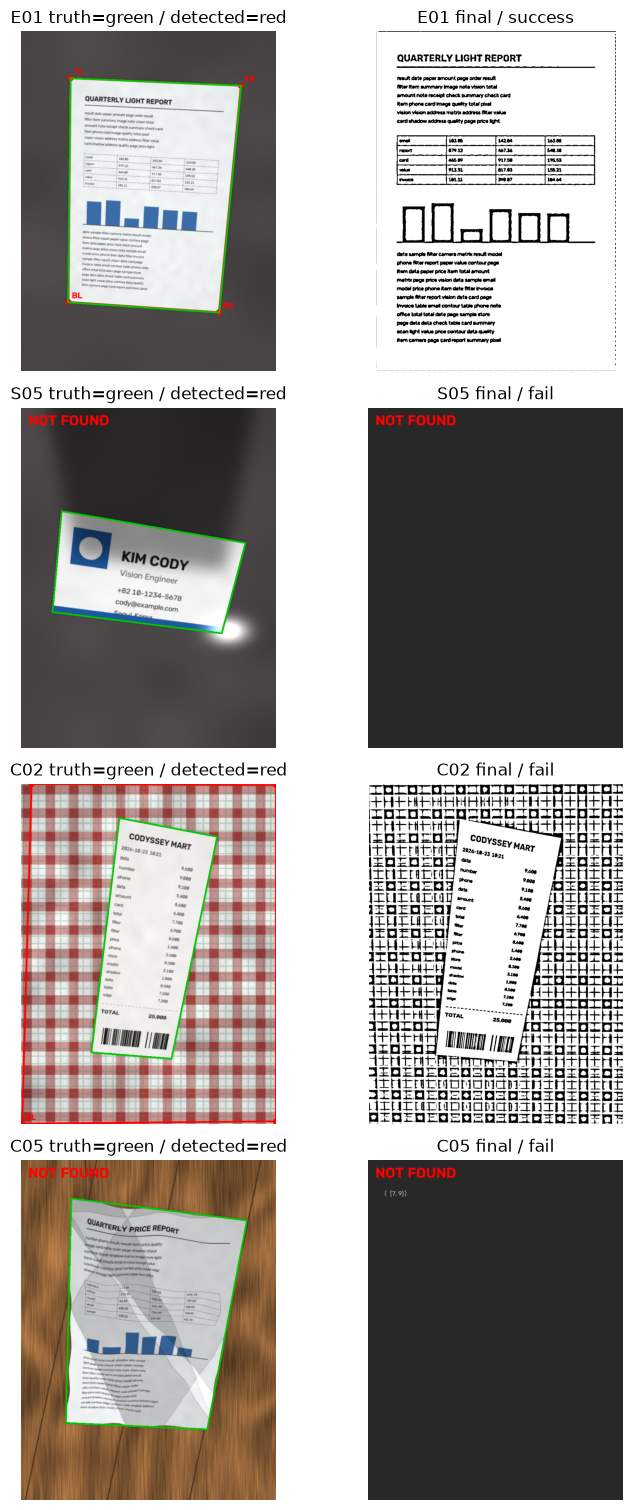

In [12]:
label, photo, row, processed = by_id['E01']
print('E01: 최대 오차', row['max_error_px'], 'px / 대각선', evaluate.diagonal(label['corners']),
      'px =', row['error_ratio']*100, '%; 판정:', row['status'])
failure_images, failure_rows = [], []
for case_id in ['E01','S05','C02','C05']:
    label, photo, row, processed = by_id[case_id]
    overlay = scanner.draw_contours(processed, show_candidates=False)
    truth_work = np.rint(np.array(label['corners'])*processed.scale).astype(np.int32)
    cv2.polylines(overlay,[truth_work],True,(0,200,0),3)
    failure_images.append((case_id+' truth=green / detected=red',overlay))
    failure_images.append((case_id+' final / '+row['status'],scanner.stage_images(processed)['5 Result']))
    failure_rows.append([case_id,row['found'],row['status'],row['candidate_vertices'],
                         round(row.get('error_ratio',float('nan'))*100,3),row['reason'] or '—'])
table(['ID','검출','정답 판정','큰 후보의 점 수','최대오차/D %','미검출 이유'],failure_rows)
show_images(failure_images,2)

## 11. 파라미터 딜레마: 기존 탐색을 현재 코드로 재현

탐색 범위는 기존 `evaluate.sweep_configs()` 그대로다. 같은 20장·266조합·판정 기준을 사용하며
결과가 잘 나오게 표본이나 조건을 고르지 않는다. 행렬의 행은 사진, 열은 조합이다.
값은 2=성공, 1=부분 성공, 0=실패. 저장된 행렬과 **전체 5,320칸**을 비교한다.
이 셀이 오래 걸리는 이유는 이미지 보간이 아니라 검출을 반복하기 때문이다(`warp=False`).

In [13]:
configs, status_matrix, sweep_ids = evaluate.parameter_sweep(dataset, params)
with np.load(root/'outputs/sweep_matrix.npz',allow_pickle=False) as stored:
    np.testing.assert_array_equal(status_matrix,stored['matrix'])
    np.testing.assert_array_equal(configs,stored['configs'])
    np.testing.assert_array_equal(sweep_ids,stored['ids'])
sweep = evaluate.sweep_summary(configs,status_matrix,sweep_ids)
assert sweep['best']['success'] == saved['sweep']['best']['success']
print('행렬:',status_matrix.shape,status_matrix.dtype,'기본:',sweep['default'])
print('최고 단일 조합:',sweep['best']['success'],'/20; 이미지별 사후 선택:',sweep['oracle_success'],'/20')
print('성공 조합이 없었던 사진:',sweep['never_success'])
print('공통 성공 조합이 없는 쌍:',sweep['disjoint_pairs'])
# 기존 실험에서 충돌한 S04/C02를 같은 전체 조합에서 읽는다.
pair_rows = []
for case_id in ['S04','C02']:
    index = sweep_ids.index(case_id)
    successes = np.flatnonzero(status_matrix[index] == 2)
    chosen = int(successes[0])
    other = 'C02' if case_id == 'S04' else 'S04'
    pair_rows.append([case_id,configs[chosen],int(status_matrix[index,chosen]),
                      other,int(status_matrix[sweep_ids.index(other),chosen])])
table(['성공시킨 사진','blur/low/high','판정 코드','다른 사진','다른 사진의 코드'],pair_rows)

행렬: (20, 266) int8 기본: {'config': [5, 50, 150], 'success': 12}
최고 단일 조합: 14 /20; 이미지별 사후 선택: 16 /20
성공 조합이 없었던 사진: ['E03', 'S05', 'C03', 'C04']
공통 성공 조합이 없는 쌍: [('S03', 'T04'), ('S04', 'C02'), ('T04', 'C02'), ('T04', 'C05')]


성공시킨 사진 | blur/low/high | 판정 코드 | 다른 사진 | 다른 사진의 코드
--- | --- | --- | --- | ---
S04 | (1, 10, 100) | 2 | C02 | 0
C02 | (1, 10, 250) | 2 | S04 | 0

기본 12/20, 탐색 범위 안의 최고 단일 조합 14/20, 이미지별 사후 선택 16/20이라는 수치는
**이 20장과 유한한 탐색 범위에 한정된 결과**다. 모든 환경에서 통하는 파라미터가 없다는 증명은 아니다.
S04와 C02는 이 범위 안에서 성공하는 조합이 겹치지 않는다.
이미지별 사후 선택은 정답을 보고 고른 상한 비교이며, 미지의 사진에 대한 자동 선택 성능이 아니다.
시연에서는 “사진마다 필요한 경계가 달라서 이 탐색 안에서는 한 조합으로 모두 성공하지 못했다”고 설명한다.

## 12. 보너스·확장: 기본 계산과 어디서 만나는가

- NumPy 컨볼루션: 2절의 한 픽셀 원소곱을 이미지 전체로 반복한다. 작은 실수 입력으로 OpenCV와 대조한다.
- 종횡비: 앱 기본 Zhang 모드는 직사각형·이미지 중심 주점·카메라 가정을 이용한다. 읽는 방향 인식은 아니다.
  기하 추정이 불가능하면 거리 기반으로 돌아간다. 거리 기반과 같은 검출 좌표에서 크기만 비교한다.
- 색 채널 엣지·자동 Canny·CLAHE 등 규칙 추가: 별도 실험이며 기본 모드를 바꾸지 않는다.
- PDF·웹캠: 기존 `src/pdf_export.py`, `src/webcam.py`를 재사용한다. PDF 저장은 검출 정확도를 높이지 않는다.

NumPy 컨볼루션 최대 차이: 0.0


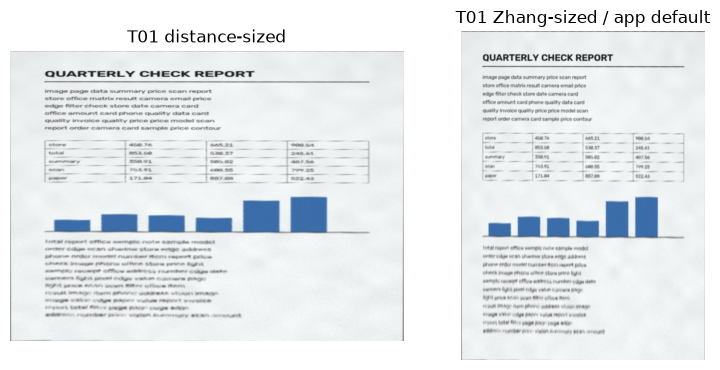

거리 W/H: 1.357843137254902 Zhang 추정: {'estimated': 0.7434134557313758, 'focal_px': 929.1311067656053, 'method': 'zhang'} 평가 정답 비율: 0.707071


규칙 실험 | 성공/20 | 기본 대비 개선 ID | 기본 대비 악화 ID
--- | --- | --- | ---
V0 기본 규칙 | 12 | [] | []
V1 닫힘 연산 제거 | 13 | ['C05'] | []
V2 + 색 채널별 엣지 | 15 | ['E03', 'S04', 'T04'] | []
V3 + 자동 Canny 임계값 | 13 | ['S04'] | []
V4 + CLAHE 대비 향상 | 13 | ['S04'] | []
V5 + 근사 허용 오차 2배 | 12 | [] | []
V6 V2~V5 모두 | 15 | ['E03', 'S04', 'T04'] | []

In [14]:
small = np.arange(49,dtype=float).reshape(7,7)
manual_full = convolution.convolve_loops(small,convolution.gaussian_kernel_2d(5))
reference = cv2.GaussianBlur(small,(5,5),0)
np.testing.assert_allclose(manual_full,reference,atol=1e-10)
print('NumPy 컨볼루션 최대 차이:',np.abs(manual_full-reference).max())
label, tilt_photo, tilt_row, tilt_result = by_id['T01']
distance_tilt, _ = scanner.warp_document(tilt_photo,tilt_result.quad,'distance')
show_images([('T01 distance-sized',distance_tilt),('T01 Zhang-sized / app default',tilt_result.warped)],2)
print('거리 W/H:',distance_tilt.shape[1]/distance_tilt.shape[0],
      'Zhang 추정:',tilt_result.aspect,'평가 정답 비율:',tilt_row['aspect_true'])
rules = evaluate.rule_experiment(dataset,params)
for current, old in zip(rules,saved['rules']):
    assert current['name'] == old['name'] and current['status'] == old['status']
rule_rows = []
for entry in rules:
    rule_rows.append([entry['name'],entry['success'],entry.get('fixed',[]),entry.get('broken',[])])
table(['규칙 실험','성공/20','기본 대비 개선 ID','기본 대비 악화 ID'],rule_rows)

규칙을 더하면 회색으로 사라진 색 경계 등을 복구할 수 있지만, 실험에서 개선된 사진과
여전히 실패하는 사진을 함께 보아야 한다. 이 결과만으로 학습 기반 모델이 더 좋다고 단정할 수 없다.
다음 접근으로 문서 분할·꼭짓점 추정을 학습할 수 있다는 가설은 세울 수 있으며, 별도 학습·평가 데이터와 비교가 필요하다.

## 13. 친구에게 시연하는 순서

A3-1 폴더에서 아래 명령을 실행한다. GUI 창은 노트북 출력과 별개다.

```powershell
uv run python -m src.app data/synthetic/E01.jpg
```

1. E01 기본값으로 다섯 창을 가리키며 입력→최종 결과를 말한다. 빨간 사각형과 문서 경계가 맞는지 본다.
2. Blur Kernel을 5→11로 바꾸며 전처리·엣지·후보가 어떻게 달라지는지 본다. 5로 되돌린다.
3. Canny를 (50,150)→(150,300)으로 바꾼 뒤 4 Contours를 함께 본다. 기본값으로 복원한다.
4. Thresh C를 10→20으로 바꾸며 결과는 달라도 윤곽선 좌표가 그대로인 이유를 설명한다.
   Thresh Block은 0=자동이며 짝수는 다음 홀수로 적용된다. 콘솔과 노트북의 실제 적용값을 확인한다.
5. `s`로 저장하고 `q`로 끝낸다. `outputs/app/scanned_E01.png`는 무손실 흑백,
   `warped_E01.jpg`는 이진화 전 컬러다. 단계별 JPEG는 시각 확인용이다.
6. 같은 명령의 파일명만 S05, C02, C05로 바꿔 다시 실행한다. 못 찾음과 잘못 찾음을 구분한다.
   C02의 결과가 반듯해도 정답 종이인지는 4 Contours와 비교해야 한다.
7. 20장 재평가와 S04/C02 충돌 표를 보여 주며 성공률의 범위를 설명한다.

거리 방식과 비교하려면 `--aspect distance`, PDF 저장을 더하려면 `--pdf`를 붙인다.
창이 없는 환경에서는 아래처럼 동일 처리 모듈의 결과를 저장한다.

```powershell
uv run python -m src.app data/synthetic/E01.jpg --no-gui --out outputs/cli
uv run python -m src.app data/synthetic/S05.jpg --no-gui --out outputs/cli
```

**스스로 설명해 보기:** 왜 축소본의 좌표를 원본으로 돌리는가? `found=True`와 성공은 어떻게 다른가?
C를 바꾸어도 배경 사각형을 고른 문제가 해결되지 않는 이유는 무엇인가?
60%는 어떤 데이터·기준의 수치이며 실제 사진에는 무엇을 더 확인해야 하는가?

더 읽기: [코드 해설](../study/code-walkthrough.md), [기존 실험 해석](../REPORT.md),
[브라우저 원리 위젯](../study/a3-1.html). 노트북의 실제 Python 출력과 브라우저 설명 위젯은 구별해서 사용한다.